# GRANAP, 5: experimental data

**What you will learn:** build a section from traits measured on a microscope image, compare it with observed tissue
areas, measure the difference, and adjust (fit) a parameter that was not measured so that the section matches the
observations.

**You need:** tutorials 1 and 2, and a little pandas. **Run time:** about 1 minute.

**About the data.** The files in `data/` are **synthetic**: `data/make_synthetic_data.py` made them from GRANAP itself,
with a known anatomy and some random noise. They stand for what the analysis of a root section image gives. Since the
true values are known, we can check that the fit finds them. Your own measurements go in files of the same form.

## 1. The data

- `measured_traits.csv`: the traits measured on the image, the inputs of the model: the stele's diameter, the
  number of cortex layers, the mean diameter of the cortex cells, the number and diameter of the metaxylem vessels
  (in mm, as GRANAP's);
- `observed_tissues.csv`: what the image's segmentation gives, to compare the model with: the section's radius and
  the area of each tissue (mm²), and the share of air in the section.

They are read with pandas:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.granap.simulation import simulate

traits = pd.read_csv("data/measured_traits.csv").set_index("trait")["value"]
observed = pd.read_csv("data/observed_tissues.csv").set_index("quantity")["value"]
traits

trait
stele_diameter          0.3208
cortex_layers           6.0000
cortex_cell_diameter    0.0449
metaxylem_vessels       6.0000
metaxylem_diameter      0.0709
Name: value, dtype: float64

In [2]:
observed

quantity
radius            0.50690
cortex_area       0.42767
stele_area        0.05461
epidermis_area    0.05553
air_share         0.13960
Name: value, dtype: float64

If your measurements are in micrometres, divide them by 1000 to get GRANAP's millimetres.

## 2. Measured traits as inputs

Each measured trait sets the parameter it corresponds to. The other parameters keep GRANAP's defaults:

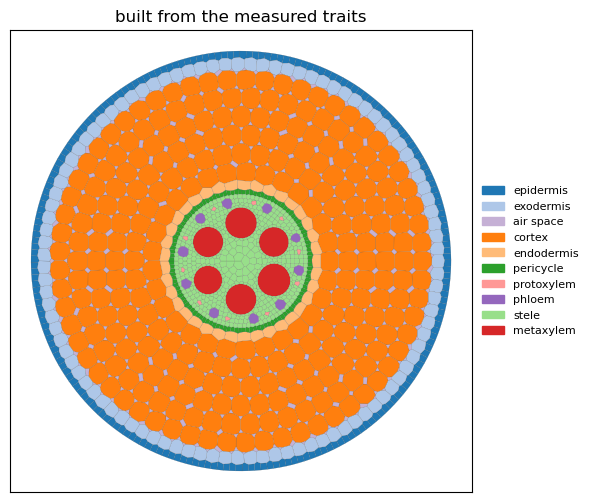

In [3]:
def from_traits(aerenchyma_proportion=0.01):
    return {"stele": {"thickness": traits["stele_diameter"]},
            "cortex": {"n_layers": int(traits["cortex_layers"]), "cell_diameter": traits["cortex_cell_diameter"],
                       "cell_width": traits["cortex_cell_diameter"]},
            "xylem": {"n_vascular_bundles": int(traits["metaxylem_vessels"]),
                      "vessel_diameter": traits["metaxylem_diameter"]},
            "aerenchyma": {"aerenchyma_proportion": aerenchyma_proportion}}


built = simulate(from_traits())
built.draw()
plt.title("built from the measured traits");

## 3. Compare with the observations

The model's tissue areas and totals next to the observed ones:

In [4]:
def compare(section):
    areas = section.summary.set_index("tissue")["area"]
    simulated = pd.Series({"radius": section.totals["radius"], "air_share": section.totals["air_share"],
                           **{f"{tissue}_area": areas.get(tissue, 0.) for tissue in ("cortex", "stele",
                                                                                     "epidermis")}})
    return pd.DataFrame({"observed": observed, "simulated": simulated.reindex(observed.index),
                         "relative difference": (simulated.reindex(observed.index) - observed) / observed})


compare(built).round(3)

,observed,simulated,relative difference
quantity,,,
radius,0.507,0.505,-0.004
cortex_area,0.428,0.514,0.202
stele_area,0.055,0.050,-0.086
epidermis_area,0.056,0.053,-0.038
air_share,0.140,0.037,-0.735


The radius matches, and the stele and epidermis are within 9 %: they follow from the measured traits. But the
**air share** is far too small and the cortex's area 20 % too large: the image shows air channels (aerenchyma) where
the section built with the default parameters has cortex cells. The proportion of aerenchyma was not measured: we fit
it.

## 4. Fit a parameter

Fitting `aerenchyma_proportion` means finding the value that makes the difference between the simulated and observed
air shares smallest. `scipy.optimize.minimize_scalar` searches it between two bounds by generating sections
repeatedly:

In [5]:
from scipy.optimize import minimize_scalar


def error(proportion):
    return abs(simulate(from_traits(proportion)).totals["air_share"] - observed["air_share"])


fit = minimize_scalar(error, bounds=(0.05, 0.5), method="bounded", options={"xatol": 0.005})
print(f"fitted aerenchyma proportion = {fit.x:.3f} after {fit.nfev} sections; "
      f"air share error {fit.fun:.4f}")
print("the value used to make the synthetic data: 0.2")

fitted aerenchyma proportion = 0.206 after 11 sections; air share error 0.0016
the value used to make the synthetic data: 0.2


,observed,simulated,relative difference
quantity,,,
radius,0.507,0.505,-0.004
cortex_area,0.428,0.433,0.011
stele_area,0.055,0.050,-0.086
epidermis_area,0.056,0.053,-0.038
air_share,0.140,0.141,0.011


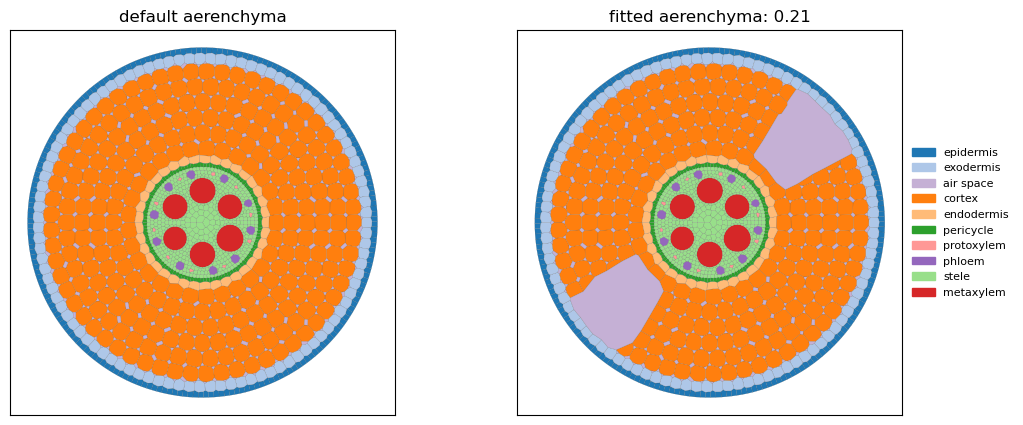

In [6]:
fitted = simulate(from_traits(fit.x))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
built.draw(axes[0], legend=False); axes[0].set_title("default aerenchyma")
fitted.draw(axes[1]); axes[1].set_title(f"fitted aerenchyma: {fit.x:.2f}")
compare(fitted).round(3)

The fitted proportion is close to the true one. GRANAP removes whole cells to form the air channels, so the air share
changes in small steps and the fit cannot be exact. The cortex's area, which was **not** used in the fit, now matches
the observation better too, since the air channels replaced cortex cells. That is a first check of the model: it
predicts an observation it was not fitted on.

With real data, you would fit on part of the observations and keep the others for this check. You would also use
several seeds (tutorial 2), since a single generated section is one draw among many.

## Try it yourself

1. Fit the cortex cells' diameter on the observed radius instead, keeping the measured layers. Do you find the
   measured diameter?
2. The epidermis' area differs a little from the observation: which parameter would you adjust?
3. Prepare a CSV of your own traits and build their section.

**Going further:** GRANAP can also build a section from the cell outlines traced on an image (ImageJ ROIs:
`openalea.granap.roi_organ.RoiOrgan`, see `example/roi_loading.py`). MECHA (MECHA-dev's tutorials) computes the water
flows through GRANAP's sections. The developer tutorials (`../developer/`) show how GRANAP is written and how it is
coupled with other models in metafspm.